# Family Matters: A Study of the Association between Public Assistance and Family Composition
### Ricardo Hernández, Ayush Bhat, Antonios Koskinas

#### Part 1: Data Cleaning

##### Import libraries

In [84]:
import pandas as pd
import statsmodels.formula.api as smf
import scipy.stats as st
import matplotlib.pyplot as plt
from statsmodels.iolib.summary2 import summary_col
import numpy as np

##### Import csv file (sourced from IPUMS USA)

In [85]:
df = pd.read_csv('/Users/tito/Downloads/sauce.csv.gz')

In [86]:
df.columns

Index(['YEAR', 'SAMPLE', 'SERIAL', 'CBSERIAL', 'HHWT', 'CLUSTER', 'STATEICP',
       'STRATA', 'GQ', 'PERNUM', 'PERWT', 'NCHILD', 'SEX', 'AGE', 'MARST',
       'RACE', 'RACED', 'HISPAN', 'HISPAND', 'HCOVANY', 'HINSCAID', 'EDUC',
       'EDUCD', 'INCTOT', 'FTOTINC', 'INCWELFR'],
      dtype='str')

##### Drop unused columns (Note: year dropped since sample is single year)

In [87]:
df = df.drop(columns=["YEAR", "SAMPLE", "CBSERIAL", "GQ", "RACED", "HISPAND", "EDUC"])

##### Filter the data by women

In [88]:
df = df[df["SEX"] == 2].copy()

##### Map and replace missing codes in INCTOT, FTOTINC and INCWELFR

In [89]:
missing_codes = {
    "INCTOT":   [9999998, 9999999],
    "FTOTINC":  [9999998, 9999999],
    "INCWELFR": [99999],
}

for col, codes in missing_codes.items():
    df[col] = df[col].replace(codes, np.nan)

##### Filter data by age (15-50)

In [90]:
df = df[df["AGE"].between(15, 50)].copy()

##### Map IPUMS USA state ICP to state names

In [91]:
icpnamemapping = {
    1: 'CONNECTICUT',
    2: 'MAINE',
    3: 'MASSACHUSETTS',
    4: 'NEWHAMPSHIRE',
    5: 'RHODEISLAND',
    6: 'VERMONT',
    11: 'DELAWARE',
    12: 'NEWJERSEY',
    13: 'NEWYORK',
    14: 'PENNSYLVANIA',
    21: 'ILLINOIS',
    22: 'INDIANA',
    23: 'MICHIGAN',
    24: 'OHIO',
    25: 'WISCONSIN',
    31: 'IOWA',
    32: 'KANSAS',
    33: 'MINNESOTA',
    34: 'MISSOURI',
    35: 'NEBRASKA',
    36: 'NORTHDAKOTA',
    37: 'SOUTHDAKOTA',
    40: 'VIRGINIA',
    41: 'ALABAMA',
    42: 'ARKANSAS',
    43: 'FLORIDA',
    44: 'GEORGIA',
    45: 'LOUISIANA',
    46: 'MISSISSIPPI',
    47: 'NORTHCAROLINA',
    48: 'SOUTHCAROLINA',
    49: 'TEXAS',
    51: 'KENTUCKY',
    52: 'MARYLAND',
    53: 'OKLAHOMA',
    54: 'TENNESSEE',
    56: 'WESTVIRGINIA',
    61: 'ARIZONA',
    62: 'COLORADO',
    63: 'IDAHO',
    64: 'MONTANA',
    65: 'NEVADA',
    66: 'NEWMEXICO',
    67: 'UTAH',
    68: 'WYOMING',
    71: 'CALIFORNIA',
    72: 'OREGON',
    73: 'WASHINGTON',
    81: 'ALASKA',
    82: 'HAWAII',
    98: 'DC'}

df['STATENAME'] = df['STATEICP'].map(icpnamemapping)

##### Create race dummy variables

In [92]:
df['BLACK'] = [1 if i==2 else 0 for i in df['RACE']]
df['AIAN'] = [1 if i==3 else 0 for i in df['RACE']]
df['API'] = [1 if i==4 or i==5 or i==6 else 0 for i in df['RACE']]
df['OTHER'] = [1 if i==7 else 0 for i in df['RACE']]
df['MULTR'] = [1 if i==8 or i==9 else 0 for i in df['RACE']]
df['HISP'] = [1 if i!=0 else 0 for i in df['HISPAN']]

##### Create dichotomous expansion state dummy variable

In [93]:
df['EXPANSION'] = [0 if i==25 or i==32 or i==41 or i==43 or i==44 or i==46 or i==48 or i==49 or i==54 or i==68 else 1 for i in df['STATEICP']]

##### Drop unused columns

In [94]:
df = df.drop(columns=['STATEICP', 'RACE', 'HISPAN'])

##### Create dichotomous welfare recipiency dummy variable using INCWELFR

In [95]:
df['WELFARE'] = np.where(
    df['INCWELFR'].isna(),
    np.nan,
    (df['INCWELFR'] > 0).astype(int)
)

##### Create personal income (excl. welfare) variable using INCTOT and INCWELFR

In [96]:
df['PRSNINC'] = df['INCTOT'] - df['INCWELFR']

##### Map medicaid codes, create interaction variable, rescale income to units of 10,000

In [97]:
medicaid_mapping = {1:0, 2:1}
df['MEDICAID'] = df['HINSCAID'].map(medicaid_mapping)
df['MEDFARE'] = df['MEDICAID'] * df['WELFARE']

df['FAMINC'] = df['FTOTINC'] - df['INCTOT']
df['PRSNINC'] = df['PRSNINC'] / 10000
df['FAMINC'] = df['FAMINC'] / 10000
df['PRSNINC2'] = df['PRSNINC'] ** 2
df['FAMINC2'] = df['FAMINC'] ** 2

df['AGE2'] = df['AGE'] ** 2

##### Create dummy variables for education level, marital status (dichotomous), and LARGEFAM for logit

In [98]:
df['HIGHSCHOOL'] = [1 if i == 63 or i==64 else 0 for i in df['EDUCD']]
df['BACHELORS'] = [1 if i == 101 else 0 for i in df['EDUCD']]
df['ADVANCED'] = [1 if i>=114 else 0 for i in df['EDUCD']]

df['MARD'] = [1 if i==1 or i==2 or i==3 else 0 for i in df['MARST']]

df['LARGEFAM'] = [1 if i >= 3 else 0 for i in df['NCHILD']]

In [99]:
df.shape

(720668, 37)

In [100]:
df.columns

Index(['SERIAL', 'HHWT', 'CLUSTER', 'STRATA', 'PERNUM', 'PERWT', 'NCHILD',
       'SEX', 'AGE', 'MARST', 'HCOVANY', 'HINSCAID', 'EDUCD', 'INCTOT',
       'FTOTINC', 'INCWELFR', 'STATENAME', 'BLACK', 'AIAN', 'API', 'OTHER',
       'MULTR', 'HISP', 'EXPANSION', 'WELFARE', 'PRSNINC', 'MEDICAID',
       'MEDFARE', 'FAMINC', 'PRSNINC2', 'FAMINC2', 'AGE2', 'HIGHSCHOOL',
       'BACHELORS', 'ADVANCED', 'MARD', 'LARGEFAM'],
      dtype='str')

#### Part 2: Regressions & Models

##### a. Initial Model

In [107]:
model_df = df[['NCHILD', 'MEDICAID', 'WELFARE', 'MEDFARE', 'AGE', 'AGE2', 'PRSNINC', 'PRSNINC2', 'FAMINC', 'FAMINC2', 'MARD']]

pred = smf.ols('NCHILD ~ MEDICAID + WELFARE + MEDFARE + AGE + AGE2 + PRSNINC + PRSNINC2 + FAMINC + FAMINC2 + MARD', data=model_df).fit()
print(pred.summary())

                            OLS Regression Results                            
Dep. Variable:                 NCHILD   R-squared:                       0.308
Model:                            OLS   Adj. R-squared:                  0.307
Method:                 Least Squares   F-statistic:                 3.013e+04
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:59:38   Log-Likelihood:            -9.7079e+05
No. Observations:              678476   AIC:                         1.942e+06
Df Residuals:                  678465   BIC:                         1.942e+06
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.5659      0.014   -180.062      0.0

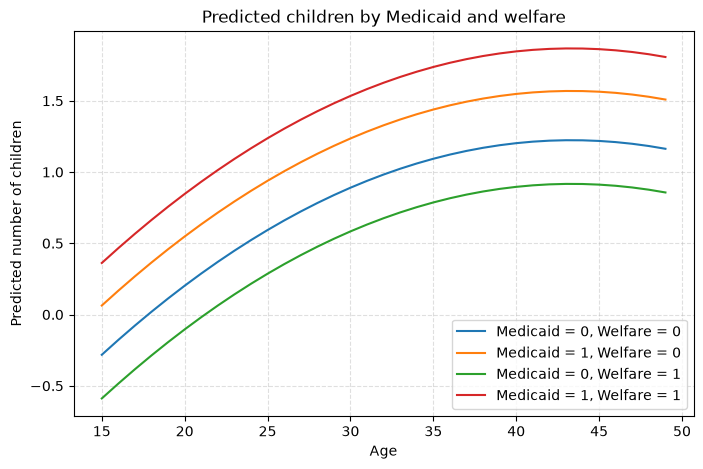

In [108]:
ages = [i for i in range(15, 50)]

plt.figure(figsize=(8, 5))
#running a loop for the pooled
for m, w in zip([0, 1, 0, 1], [0, 0, 1, 1]):
    new = pd.DataFrame({'AGE': ages,
                        'MEDICAID': [m for i in ages],
                        'WELFARE': [w for i in ages],
                        'PRSNINC': [model_df['PRSNINC'].mean() for i in ages],
                        'FAMINC': [model_df['FAMINC'].mean() for i in ages],
                        'MARD': [model_df['MARD'].mean() for i in ages]})
 #same interaction terms for the model
    new['AGE2'] = new['AGE']**2
    new['PRSNINC2'] = new['PRSNINC']**2
    new['FAMINC2'] = new['FAMINC']**2
    new['MEDFARE'] = new['MEDICAID'] * new['WELFARE']

    plt.plot(ages, pred.predict(new), label=f'Medicaid = {m}, Welfare = {w}')

plt.xlabel('Age')
plt.ylabel('Predicted number of children')
plt.title('Predicted children by Medicaid and welfare')
plt.legend()
plt.grid(alpha=0.4, ls='--')
plt.show()

##### b. National Level Baseline Model

In [101]:
#initial model
ols_base = 'NCHILD ~ MEDICAID + WELFARE + MEDFARE + AGE + AGE2 + PRSNINC + PRSNINC2 + FAMINC + FAMINC2 + MARD + BLACK + AIAN + API + OTHER + MULTR + HISP + HIGHSCHOOL + BACHELORS + ADVANCED'

reg_base = smf.ols(ols_base, data=df).fit()
print(reg_base.summary())

                            OLS Regression Results                            
Dep. Variable:                 NCHILD   R-squared:                       0.317
Model:                            OLS   Adj. R-squared:                  0.317
Method:                 Least Squares   F-statistic:                 1.654e+04
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:59:37   Log-Likelihood:            -9.6634e+05
No. Observations:              678476   AIC:                         1.933e+06
Df Residuals:                  678456   BIC:                         1.933e+06
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.7656      0.014   -192.209      0.0

In [102]:
results = summary_col(
    [reg_base],
    model_names=['Baseline'],
    regressor_order=['MEDICAID', 'WELFARE', 'MEDFARE','AGE', 'AGE2', 'PRSNINC', 'PRSNINC2', 'FAMINC', 'FAMINC2','MARD', 'BLACK', 'AIAN', 'API', 'OTHER', 'MULTR', 'HISP','HIGHSCHOOL', 'BACHELORS', 'ADVANCED', 'Intercept'],
    stars=True,
    float_format='%0.5f',
    info_dict={'Observations': lambda x: f'{int(x.nobs):,}'},
    drop_omitted=True
)

print(results)


                 Baseline 
--------------------------
MEDICAID       0.31211*** 
               (0.00347)  
WELFARE        -0.32856***
               (0.02196)  
MEDFARE        0.61216*** 
               (0.02447)  
AGE            0.17769*** 
               (0.00093)  
AGE2           -0.00209***
               (0.00001)  
PRSNINC        -0.02813***
               (0.00041)  
PRSNINC2       0.00044*** 
               (0.00001)  
FAMINC         0.01285*** 
               (0.00022)  
FAMINC2        -0.00011***
               (0.00000)  
MARD           0.74744*** 
               (0.00299)  
BLACK          0.05794*** 
               (0.00456)  
AIAN           0.13044*** 
               (0.01035)  
API            -0.15332***
               (0.00462)  
OTHER          0.00391    
               (0.00605)  
MULTR          -0.02984***
               (0.00441)  
HISP           0.09236*** 
               (0.00432)  
HIGHSCHOOL     -0.08644***
               (0.00339)  
BACHELORS      -0.23818***


In [103]:
print(f'MEDICAID * WELFARE T TEST', reg_base.t_test("MEDFARE = 0"), sep='\n\n')

MEDICAID * WELFARE T TEST

                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.6122      0.024     25.018      0.000       0.564       0.660


In [104]:
print(f'MEDICAID + (MEDICAID * WELFARE) T TEST', reg_base.t_test("MEDICAID + MEDFARE = 0"), sep='\n\n')

MEDICAID + (MEDICAID * WELFARE) T TEST

                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.9243      0.024     38.126      0.000       0.877       0.972


In [105]:
print(f'WELFARE + (MEDICAID * WELFARE) T TEST', reg_base.t_test("WELFARE + MEDFARE = 0"), sep='\n\n')

WELFARE + (MEDICAID * WELFARE) T TEST

                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.2836      0.011     26.119      0.000       0.262       0.305


In [106]:
ftest = reg_base.f_test("MEDICAID = 0, WELFARE = 0, MEDFARE = 0")
print(f'JOINT SIGNIFICANCE F TEST', ftest, sep='\n\n')

JOINT SIGNIFICANCE F TEST

<F test: F=3578.290236369179, p=0.0, df_denom=6.78e+05, df_num=3>


##### c. Expansion Model & One-Way State Fixed Effects Model

In [109]:
ols_exp = 'NCHILD ~ MEDICAID + WELFARE + MEDFARE + AGE + AGE2 + PRSNINC + PRSNINC2 + FAMINC + FAMINC2 + MARD + BLACK + AIAN + API + OTHER + MULTR + HISP + EXPANSION + HIGHSCHOOL + BACHELORS + ADVANCED'
ols_fe = 'NCHILD ~ MEDICAID + WELFARE + MEDFARE + AGE + AGE2 + PRSNINC + PRSNINC2 + FAMINC + FAMINC2 + MARD + BLACK + AIAN + API + OTHER + MULTR + HISP + C(STATENAME, Treatment("FLORIDA")) + HIGHSCHOOL + BACHELORS + ADVANCED'

In [110]:
reg_exp = smf.ols(ols_exp, data=df).fit()
reg_fe = smf.ols(ols_fe, data=df).fit()

In [111]:
results = summary_col(
    [reg_exp, reg_fe],
    model_names=['Expansion', 'One-Way State Fixed Effects'],
    regressor_order=['MEDICAID', 'WELFARE', 'MEDFARE', 'EXPANSION', 'AGE', 'AGE2', 'PRSNINC', 'PRSNINC2', 'FAMINC', 'FAMINC2'],
    stars=True,
    float_format='%0.5f',
    info_dict={
        'Observations': lambda x: f'{int(x.nobs):,}'
    },
    drop_omitted=True
)

print(results)


                Expansion  One-Way State Fixed Effects
------------------------------------------------------
MEDICAID       0.31545***  0.32748***                 
               (0.00349)   (0.00351)                  
WELFARE        -0.32724*** -0.30899***                
               (0.02196)   (0.02190)                  
MEDFARE        0.61130***  0.59881***                 
               (0.02447)   (0.02440)                  
EXPANSION      -0.02219***                            
               (0.00280)                              
AGE            0.17777***  0.17901***                 
               (0.00093)   (0.00093)                  
AGE2           -0.00209*** -0.00211***                
               (0.00001)   (0.00001)                  
PRSNINC        -0.02794*** -0.02652***                
               (0.00041)   (0.00041)                  
PRSNINC2       0.00044***  0.00042***                 
               (0.00001)   (0.00001)                  
FAMINC   

In [112]:
print(f'EXPANSION T TEST', reg_exp.t_test("EXPANSION = 0"), sep='\n\n')

EXPANSION T TEST

                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0222      0.003     -7.914      0.000      -0.028      -0.017


In [113]:
print(f'MEDICAID * WELFARE T TEST', reg_fe.t_test("MEDFARE = 0"), sep='\n\n')

MEDICAID * WELFARE T TEST

                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.5988      0.024     24.538      0.000       0.551       0.647


In [114]:
ftest = reg_fe.f_test("MEDICAID = 0, WELFARE = 0, MEDFARE = 0")
print(f'JOINT SIGNIFICANCE F TEST', ftest, sep='\n\n')

JOINT SIGNIFICANCE F TEST

<F test: F=3817.0254949135415, p=0.0, df_denom=6.78e+05, df_num=3>


##### d. Logit Expansion Model & Logit One-Way State Fixed Effects Model

In [115]:
races = 'BLACK + AIAN + API + OTHER + MULTR + HISP'
educs = 'HIGHSCHOOL + BACHELORS + ADVANCED'

log = f'LARGEFAM ~ MEDICAID + WELFARE + MEDFARE + AGE + AGE2 + PRSNINC + PRSNINC2 + FAMINC + FAMINC2 + MARD + {races} + {educs} + C(STATENAME, Treatment("FLORIDA"))'
logres = smf.logit(log, data=df).fit()

lex = f'LARGEFAM ~ MEDICAID + WELFARE + MEDFARE + EXPANSION + AGE + AGE2 + PRSNINC + PRSNINC2 + FAMINC + FAMINC2 + MARD + {races} + {educs}'
lexres = smf.logit(lex,data=df).fit()


Optimization terminated successfully.
         Current function value: 0.282860
         Iterations 9
Optimization terminated successfully.
         Current function value: 0.284784
         Iterations 9


In [116]:
print(logres.summary().tables[1])
log_mf = logres.get_margeff(method='dydx',at='mean')
print(log_mf.summary())

                                                          coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------------
Intercept                                             -19.9450      0.127   -157.587      0.000     -20.193     -19.697
C(STATENAME, Treatment("FLORIDA"))[T.ALABAMA]           0.3550      0.039      9.218      0.000       0.280       0.430
C(STATENAME, Treatment("FLORIDA"))[T.ALASKA]            0.6866      0.085      8.082      0.000       0.520       0.853
C(STATENAME, Treatment("FLORIDA"))[T.ARIZONA]           0.3928      0.034     11.688      0.000       0.327       0.459
C(STATENAME, Treatment("FLORIDA"))[T.ARKANSAS]          0.3285      0.046      7.072      0.000       0.237       0.420
C(STATENAME, Treatment("FLORIDA"))[T.CALIFORNIA]        0.1470      0.023      6.434      0.000       0.102       0.192
C(STATENAME, Treatment("FLORIDA"))[T.COL

In [117]:
print(lexres.summary().tables[1])
lex_mf = lexres.get_margeff(method='dydx',at='mean')
print(lex_mf.summary())

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -19.4055      0.125   -155.766      0.000     -19.650     -19.161
MEDICAID       0.7283      0.012     62.988      0.000       0.706       0.751
WELFARE       -0.4108      0.094     -4.362      0.000      -0.595      -0.226
MEDFARE        0.6158      0.098      6.265      0.000       0.423       0.808
EXPANSION     -0.0245      0.009     -2.592      0.010      -0.043      -0.006
AGE            0.8885      0.007    133.622      0.000       0.875       0.902
AGE2          -0.0113   8.72e-05   -129.515      0.000      -0.011      -0.011
PRSNINC       -0.0647      0.001    -49.032      0.000      -0.067      -0.062
PRSNINC2       0.0009    2.4e-05     36.366      0.000       0.001       0.001
FAMINC         0.0243      0.001     27.756      0.000       0.023       0.026
FAMINC2       -0.0002   1.37e-05    -15.922      0.0

In [118]:
df['yhat_log'] = pd.Series(logres.predict(df), index=logres.model.data.row_labels)
df['yhat_lex'] = pd.Series(lexres.predict(df), index=lexres.model.data.row_labels)

In [119]:
comp = 0
results_mat = 0

for c in [i/1000 for i in range(200,800,1)]:
    yhat_log = [1 if i >= c else 0 for i in df[df['yhat_log'].isna()==False]['yhat_log']]
    cm = pd.crosstab(df[df['yhat_log'].isna()==False]['LARGEFAM'], yhat_log, margins = True)
    acc = (cm[0][0] + cm[1][1]) / (cm['All']['All'])
    err = 1 - acc
    sen = cm[1][1] / cm['All'][1]
    spe = cm[0][0] / cm['All'][0]
   
    avg = (1/2) * (acc + (1/2)*(spe+sen)) #weighted average of accuracy,specificity and sensitivity
    if avg > comp:
        comp = avg
        results_mat = [c,acc, err, sen, spe]

In [120]:
results_mat = [c,acc, err, sen, spe]
results_df = pd.DataFrame({'Name':['Cutoff (y=1)','Accuracy','Error','Sensitivity','Specificity'], 'Number':results_mat})
print(results_df)

           Name    Number
0  Cutoff (y=1)  0.799000
1      Accuracy  0.888509
2         Error  0.111491
3   Sensitivity  0.000040
4   Specificity  0.999982


In [121]:
print(cm)
print(results_df)

col_0          0   1     All
LARGEFAM                    
0         602829  11  602840
1          75633   3   75636
All       678462  14  678476
           Name    Number
0  Cutoff (y=1)  0.799000
1      Accuracy  0.888509
2         Error  0.111491
3   Sensitivity  0.000040
4   Specificity  0.999982


In [122]:
compx = 0
results_mat_x = 0

for cx in [i/1000 for i in range(200,800,1)]:
    yhat_lex = [1 if i >= cx else 0 for i in df[df['yhat_lex'].isna()==False]['yhat_lex']]
    cmx = pd.crosstab(df[df['yhat_lex'].isna()==False]['LARGEFAM'], yhat_lex, margins = True)
    accx = (cmx[0][0] + cmx[1][1]) / (cmx['All']['All'])
    errx = 1 - acc
    senx = cmx[1][1] / cmx['All'][1]
    spex = cmx[0][0] / cmx['All'][0]
   
    avgx = (1/2) * (accx + (1/2)*(spex+senx)) #weighted average of accuracy,specificity and sensitivity
    if avgx > compx:
        compx = avgx
        results_mat_x = [cx,accx, errx, senx, spex]

In [123]:
results_dfx = pd.DataFrame({'Name':['Cutoff (y=1)','Accuracy','Error','Sensitivity','Specificity'], 'Number':results_mat_x})
print(results_dfx)

           Name    Number
0  Cutoff (y=1)  0.226000
1      Accuracy  0.826007
2         Error  0.111491
3   Sensitivity  0.447988
4   Specificity  0.873436


In [124]:
print(cmx)

col_0          0   1     All
LARGEFAM                    
0         602828  12  602840
1          75634   2   75636
All       678462  14  678476


In [125]:
print('comp:',comp)
print('compx:',compx)

comp: 0.7470524841391077
compx: 0.7433594220811066


In [127]:
coeffs_logit = summary_col(
    [lexres, logres],
    model_names=['Expansion', 'One-Way State Fixed Effects'],
    regressor_order=['MEDICAID', 'WELFARE', 'MEDFARE', 'EXPANSION', 'AGE', 'AGE2', 'PRSNINC', 'PRSNINC2', 'FAMINC', 'FAMINC2'],
    stars=True,
    float_format='%0.5f',
    info_dict={
        'Observations': lambda x: f'{int(x.nobs):,}'
    },
    drop_omitted=True
    
)

print(coeffs_logit)


              Expansion  One-Way State Fixed Effects
----------------------------------------------------
MEDICAID     0.72828***  0.77247***                 
             (0.01156)   (0.01171)                  
WELFARE      -0.41084*** -0.36536***                
             (0.09420)   (0.09442)                  
MEDFARE      0.61583***  0.58172***                 
             (0.09829)   (0.09852)                  
EXPANSION    -0.02452***                            
             (0.00946)                              
AGE          0.88850***  0.89494***                 
             (0.00665)   (0.00667)                  
AGE2         -0.01130*** -0.01138***                
             (0.00009)   (0.00009)                  
PRSNINC      -0.06471*** -0.06159***                
             (0.00132)   (0.00133)                  
PRSNINC2     0.00087***  0.00085***                 
             (0.00002)   (0.00002)                  
FAMINC       0.02431***  0.02605***          

In [128]:
print(f'EXPANSION T TEST', lexres.t_test("EXPANSION = 0"), sep='\n\n')

EXPANSION T TEST

                             Test for Constraints                             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0245      0.009     -2.592      0.010      -0.043      -0.006


In [129]:
print(f'MEDICAID * WELFARE T TEST', logres.t_test("MEDFARE = 0"), sep='\n\n')

MEDICAID * WELFARE T TEST

                             Test for Constraints                             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.5817      0.099      5.905      0.000       0.389       0.775


In [130]:
ftest = logres.f_test("MEDICAID = 0, WELFARE = 0, MEDFARE = 0")
print(f'JOINT SIGNIFICANCE F TEST', ftest, sep='\n\n')

JOINT SIGNIFICANCE F TEST

<F test: F=1666.8597916995598, p=0.0, df_denom=6.78e+05, df_num=3>


In [131]:
fuhtest = lexres.f_test("MEDICAID = 0, WELFARE = 0, MEDFARE = 0, EXPANSION = 0")
print(f'JOINT SIGNIFICANCE F TEST', fuhtest, sep='\n\n')

JOINT SIGNIFICANCE F TEST

<F test: F=1157.8243177833979, p=0.0, df_denom=6.78e+05, df_num=4>
